# Project2 - Host program

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import time

from pynq import Overlay
from pynq import allocate


ol = Overlay('design_1.bit')

# Download your bitstream to FPGA
t_before_bitstream = time.time()
ol.download()
t_after_bitstream = time.time()

print(t_after_bitstream - t_before_bitstream, 'seconds to program bitstream')
# print the names 
ol.ip_dict.keys()

0.12875914573669434 seconds to program bitstream


dict_keys(['phasedetector_0', 'axi_dma_0', 'axi_dma_1', 'processing_system7_0'])

In [22]:
dmaIR = ol.axi_dma_0 # First DMA -> This needs to change based on the design name from lab Multi DMA
dmaQT = ol.axi_dma_1 # Second DMA -> This needs to change based on the design name from lab Multi DMA
ph_ip = ol.phasedetector_0 # Your IP


In [23]:
length = 1024

# Open input/output files
fI = open('input_i.dat','r')
fQ = open('input_q.dat','r')
fG = open('out_gold.dat', 'r')

# Allocate regular numpy arrays to store input and output
inp_I = np.empty([length,], dtype=np.float32)
inp_Q = np.empty([length,], dtype=np.float32)
golden_R = np.empty([length,], dtype=np.float32)
golden_T = np.empty([length,], dtype=np.float32)

# Store data into arrays
for i in range (0, length):
    golden_R[i], golden_T[i] = [np.float32(x) for x in next(fG).split()]
    inp_I[i] = np.float32(next(fI))
    inp_Q[i] = np.float32(next(fQ))

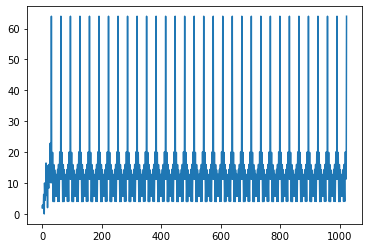

In [24]:
plt.plot(golden_R)

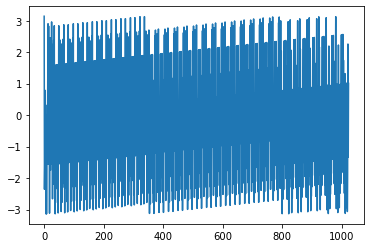

In [25]:
plt.plot(golden_T)

In [26]:
print("Golden thetas at the R peaks are:\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n".format(golden_T[31],golden_T[63],golden_T[95],golden_T[127],golden_T[159],golden_T[191],golden_T[223],golden_T[255],golden_T[287],golden_T[319],golden_T[351],golden_T[383],golden_T[415],golden_T[447],golden_T[479],golden_T[511]))

Golden thetas at the R peaks are:
 0.015529000200331211
 0.047508999705314636
 0.07948499917984009
 0.1115259975194931
 0.1434909999370575
 0.1754709929227829
 0.2074970006942749
 0.23947599530220032
 0.27150198817253113
 0.3034819960594177
 0.3355030119419098
 0.367482990026474
 0.399507999420166
 0.4314880073070526
 0.4635140001773834
 0.49549400806427



## Complete the following block

In [27]:
# Allocate CMA array for DMA
in_bufferI = allocate(shape=(length,), dtype=np.float32)
in_bufferQ = allocate(shape=(length,), dtype=np.float32)
out_bufferR = allocate(shape=(length,), dtype=np.float32)
out_bufferT = allocate(shape=(length,), dtype=np.float32)

# Copy regular numpy arrays to CMA arrays
np.copyto(in_bufferI, inp_I)
np.copyto(in_bufferQ, inp_Q)

# Write length using MMIO (we got the address from Vivado)
ph_ip.write(0x0, 0x1)

t_start = time.time()
# Begin data transfer from/to DMA
dmaIR.recvchannel.transfer(out_bufferR)
dmaQT.recvchannel.transfer(out_bufferT)
dmaIR.sendchannel.transfer(in_bufferI)
dmaQT.sendchannel.transfer(in_bufferQ)
dmaIR.sendchannel.wait()
dmaQT.sendchannel.wait()
dmaIR.recvchannel.wait()
dmaQT.recvchannel.wait()
t_stop = time.time()


print(t_after_bitstream - t_before_bitstream, 'seconds to execute on hardware')

0.12875914573669434 seconds to execute on hardware


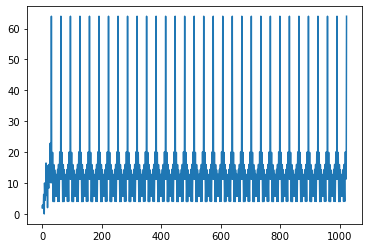

In [28]:
plt.plot(out_bufferR)

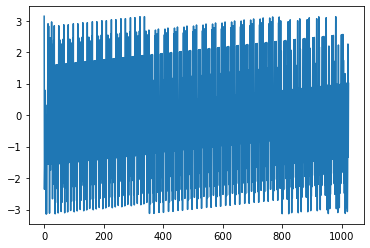

In [29]:
plt.plot(out_bufferT)

In [30]:
print("Output thetas at the R peaks are:\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n {}\n".format(out_bufferT[31],out_bufferT[63],out_bufferT[95],out_bufferT[127],out_bufferT[159],out_bufferT[191],out_bufferT[223],out_bufferT[255],out_bufferT[287],out_bufferT[319],out_bufferT[351],out_bufferT[383],out_bufferT[415],out_bufferT[447],out_bufferT[479],out_bufferT[511]))

# Free the CMA buffers
del in_bufferI, in_bufferQ, out_bufferR, out_bufferT

Output thetas at the R peaks are:
 0.015529096126556396
 0.04750877618789673
 0.07948523759841919
 0.11152631044387817
 0.143490731716156
 0.1754705309867859
 0.20749658346176147
 0.2394762635231018
 0.2715023159980774
 0.3034818768501282
 0.3355026841163635
 0.3674824833869934
 0.399508535861969
 0.4314880967140198
 0.46351391077041626
 0.49549371004104614

